# P3 Movie Genre — Notebook 3: Interpretability

Notebook 2 measured how well the models do. This notebook asks **what they are doing**. Everything here uses the three TF-IDF logistic regression models (Comedy, Horror, Romance) exported by Notebook 2.

| Section | Contents |
|---|---|
| 1 | Setup: rebuild the test set, load vectorizer, scaler and models |
| 2 | Coefficients: top 10 words toward and away from each genre |
| 3 | SHAP (`LinearExplainer`) for Horror: mean \|SHAP\| bar plot vs. coefficients, beeswarm |
| 4 | Individual predictions: waterfall plots for a confident hit and a bad miss |

In [1]:
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import shap
from sklearn.metrics import f1_score

sns.set_theme(style="whitegrid")
pd.set_option("display.precision", 3)

DATA_PATH = Path("../data/mpst_imdb_movies.csv")
MODELS_DIR = Path("../models")
VOTE_MIN = 1000          # chosen in Notebook 1, section 1.3
GENRES = ["Comedy", "Horror", "Romance"]


def slug(genre):
    return genre.lower().replace("-", "")

/opt/miniconda3/envs/msds565/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. Setup
Read the data, apply the same vote filter, and rebuild Notebook 2's split from the `split` column. The **test set** is what we explain. The **training set** is needed only as SHAP's background distribution (§3). The vectorizer, scaler and models are loaded exactly as Notebook 2 saved them.

In [2]:
df = pd.read_csv(DATA_PATH)
df["numVotes"] = pd.to_numeric(df["numVotes"], errors="coerce")
df = df[df["numVotes"] >= VOTE_MIN].reset_index(drop=True)
train_df = df[df["split"].isin(["train", "val"])].reset_index(drop=True)
test_df = df[df["split"] == "test"].reset_index(drop=True)

tfidf = joblib.load(MODELS_DIR / "P3_N2_tfidf_vectorizer.pkl")
scaler = joblib.load(MODELS_DIR / "P3_N2_tfidf_scaler.pkl")
models = {g: joblib.load(MODELS_DIR / f"P3_N2_tfidf_logreg_{slug(g)}.pkl") for g in GENRES}
vocab = tfidf.get_feature_names_out()

Xtr = scaler.transform(tfidf.transform(train_df["plot_synopsis"]))
Xte_raw = tfidf.transform(test_df["plot_synopsis"])
Xte = scaler.transform(Xte_raw)
print(f"train: {len(train_df):,}   test: {len(test_df):,}   vocabulary: {len(vocab):,}")

train: 9,996   test: 2,526   vocabulary: 10,000


As a sanity check, the reloaded models should reproduce the TF-IDF rows of Notebook 2's leaderboard exactly.

In [3]:
pd.Series({g: f1_score(test_df[g], models[g].predict(Xte), average="macro") for g in GENRES},
          name="test macro-F1").to_frame().T

,Comedy,Horror,Romance
test macro-F1,0.737,0.846,0.715


## 2. Coefficients
For each genre: the 10 largest positive coefficients (pushing toward the genre, green) and the 10 largest negative ones (pushing away, red). Because Notebook 2 standardized every TF-IDF feature to unit variance, a coefficient means "change in log-odds per one standard deviation of this word's TF-IDF weight". That makes sizes comparable across words.

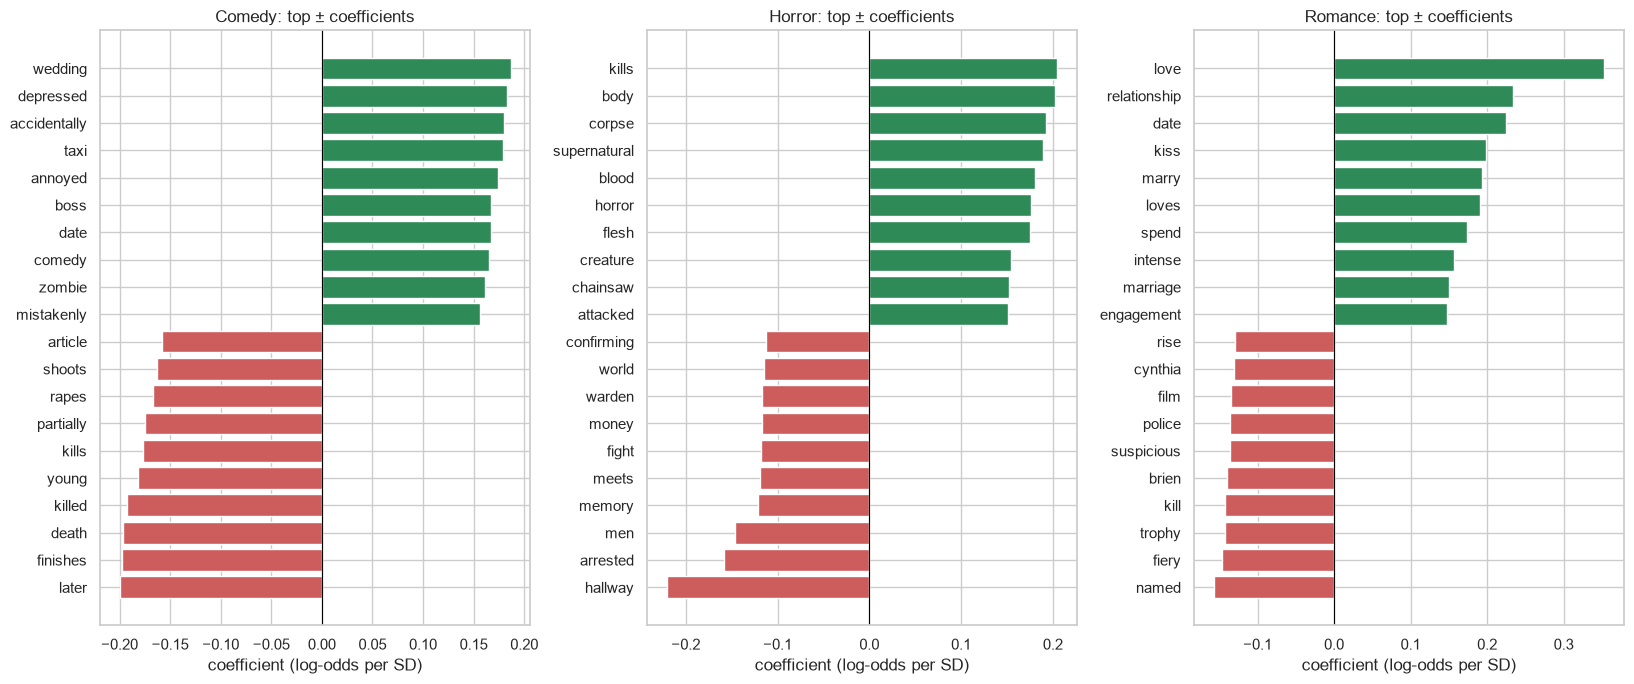

In [4]:
fig, axes = plt.subplots(1, len(GENRES), figsize=(5.5 * len(GENRES), 7))
for ax, g in zip(axes, GENRES):
    coefs = pd.Series(models[g].coef_[0], index=vocab)
    top = pd.concat([coefs.nlargest(10), coefs.nsmallest(10).iloc[::-1]]).iloc[::-1]
    ax.barh(top.index, top.values, color=np.where(top.values > 0, "seagreen", "indianred"))
    ax.axvline(0, color="black", lw=0.8)
    ax.set(title=f"{g}: top ± coefficients", xlabel="coefficient (log-odds per SD)")
plt.tight_layout()
plt.show()

**TODO (write after running):** are the positive words genuine genre vocabulary (e.g. Horror: *demon, haunted*; Romance: *love, marry*; Comedy: *hilarious, wacky*), or names and quirks of this corpus? What sits on the negative side? Often it's the vocabulary of neighboring or opposite genres (e.g. *kills, police* pushing away from Comedy), which ties back to Notebook 1's correlation heatmap.

## 3. SHAP for Horror
**Why Horror:** it has the most distinctive vocabulary of our three genres, so its explanations should be the easiest to check against intuition.

For a linear model with independent features, `LinearExplainer` gives each word's contribution to one movie's log-odds as **coefficient × (that movie's feature value − the background mean)**. The background is the full training set, the same data the model learned from. All SHAP values are in **log-odds** units.

In [5]:
SHAP_GENRE = "Horror"
model = models[SHAP_GENRE]

explainer = shap.LinearExplainer(model, shap.maskers.Independent(Xtr, max_samples=Xtr.shape[0]))
sv = np.asarray(explainer.shap_values(Xte))
base_value = float(np.ravel(explainer.expected_value)[0])
print(f"SHAP matrix: {sv.shape[0]:,} test movies × {sv.shape[1]:,} words; base value = {base_value:.3f} log-odds")

SHAP matrix: 2,526 test movies × 10,000 words; base value = -6.349 log-odds


### 3.1 Mean |SHAP| per word vs. coefficients
A coefficient says how much a word **could** move a prediction. Mean |SHAP| says how much it **actually does** move predictions, averaged over the test set. The table lines up both rankings and adds each word's **document frequency** (the share of test synopses containing it).

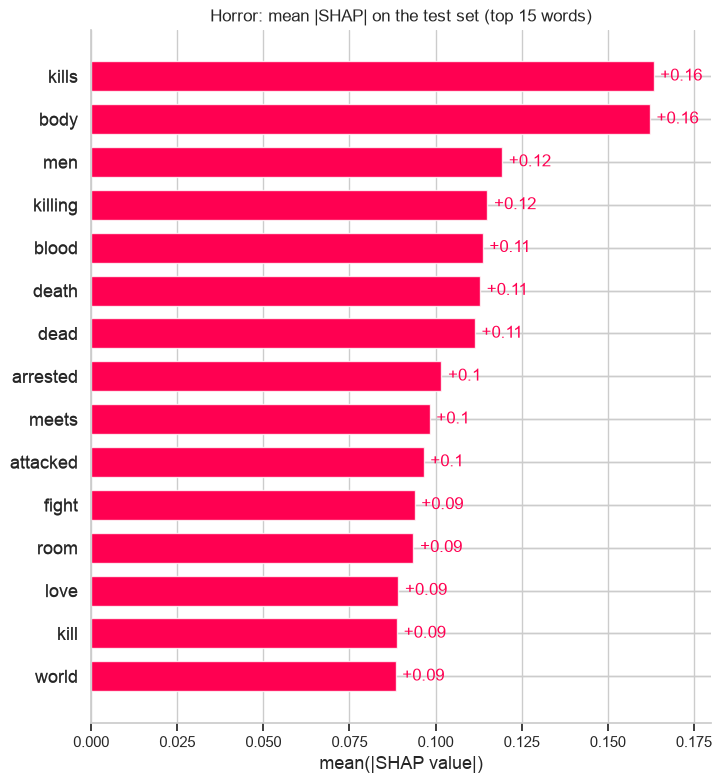

In [6]:
mean_abs = pd.Series(np.abs(sv).mean(axis=0), index=vocab)
top_idx = np.argsort(-mean_abs.to_numpy())[:15]

expl_top = shap.Explanation(values=sv[:, top_idx], base_values=np.full(len(sv), base_value),
                            data=Xte_raw[:, top_idx].toarray(), feature_names=list(vocab[top_idx]))
shap.plots.bar(expl_top, max_display=15, show=False)
plt.title(f"{SHAP_GENRE}: mean |SHAP| on the test set (top 15 words)")
plt.show()

In [7]:
coefs = pd.Series(model.coef_[0], index=vocab)
doc_freq = pd.Series(np.asarray((Xte_raw > 0).mean(axis=0)).ravel(), index=vocab)
coef_rank = coefs.abs().rank(ascending=False).astype(int)
top_coef_words = coefs.abs().nlargest(10).index

pd.concat({
    "top by mean |SHAP|": pd.DataFrame({
        "word": vocab[top_idx[:10]], "mean_|SHAP|": mean_abs.iloc[top_idx[:10]].values,
        "coef": coefs.iloc[top_idx[:10]].values, "|coef| rank": coef_rank.iloc[top_idx[:10]].values,
        "doc_freq": doc_freq.iloc[top_idx[:10]].values}),
    "top by |coef|": pd.DataFrame({
        "word": top_coef_words, "mean_|SHAP|": mean_abs[top_coef_words].values,
        "coef": coefs[top_coef_words].values, "|coef| rank": coef_rank[top_coef_words].values,
        "doc_freq": doc_freq[top_coef_words].values}),
}, axis=1)

top by mean |SHAP|                                         top by |coef|  \
                word mean_|SHAP|   coef |coef| rank doc_freq          word   
0              kills       0.163  0.205           2    0.268       hallway   
1               body       0.162  0.202           3    0.281         kills   
2                men       0.119 -0.146          16    0.298          body   
3            killing       0.115  0.149          14    0.251        corpse   
4              blood       0.114  0.180           6    0.148  supernatural   
5              death       0.113  0.131          25    0.387         blood   
6               dead       0.111  0.131          24    0.334        horror   
7           arrested       0.102 -0.158           9    0.130         flesh   
8              meets       0.098 -0.119          36    0.322      arrested   
9           attacked       0.097  0.151          12    0.133      creature   

                                           
  mean_|SHAP|   coef |coef| rank doc_freq  
0       0.061 -0.221           1    0.023  
1       0.163  0.205           2    0.268  
2       0.162  0.202           3    0.281  
3       0.080  0.192           4    0.057  
4       0.046  0.190           5    0.019  
5       0.114  0.180           6    0.148  
6       0.076  0.176           7    0.058  
7       0.048  0.175           8    0.024  
8       0.102 -0.158           9    0.130  
9       0.059  0.154          10    0.050

**How the rankings differ, and why.** For one word, mean |SHAP| is roughly |coefficient| × the average distance of its value from the mean. A word that appears in very few synopses is almost always 0, which is right at its (near-zero) mean. So it contributes almost nothing to most predictions, however large its coefficient. A word with a moderate coefficient that appears in many synopses, at varying weights, adds up to a large average effect.

**TODO (write after running):** point to specific words in the table. Find a high-|coef|-rank word with low document frequency that drops down the SHAP ranking, and a frequent word that climbs it.

### 3.2 Beeswarm
Each dot is one test movie. Its horizontal position is that word's SHAP value for that movie, and its color is the word's TF-IDF weight in the movie (red = high, blue = absent or low).

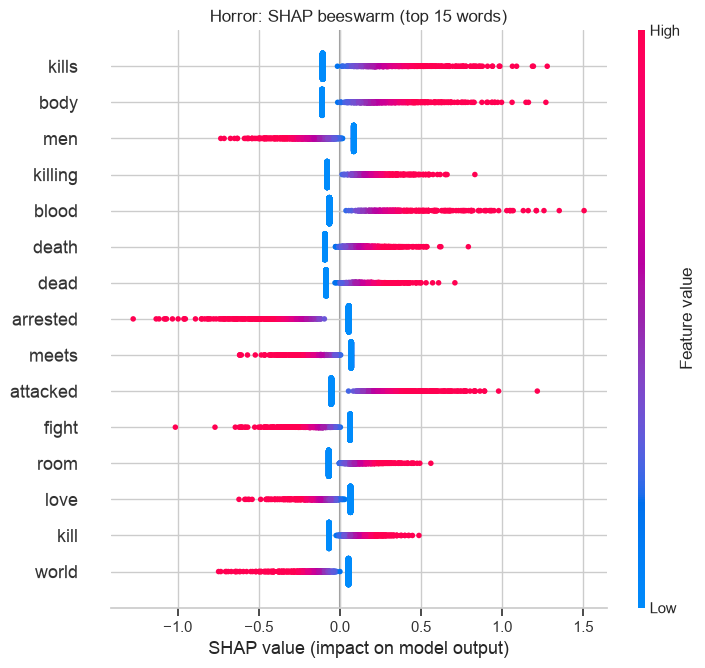

In [8]:
shap.plots.beeswarm(expl_top, max_display=15, show=False)
plt.title(f"{SHAP_GENRE}: SHAP beeswarm (top 15 words)")
plt.show()

**What the beeswarm shows that the bar plot hides:**
- **Direction:** whether a word pushes *toward* Horror (red dots on the right) or away from it.
- **Asymmetry:** for most words, absence (blue) gives a tight cluster of small negative values just left of zero, while presence (red) gives a long tail of large pushes. Two words with the same mean |SHAP| can get it from rare big pushes or from many small ones. The bar plot can't tell those apart.
- **Spread:** how much a word's effect varies across movies, depending on how heavily the synopsis uses it.

**TODO (write after running):** describe one or two specific words that show these patterns.

## 4. Individual predictions
Two test movies for the Horror model:
- **Confidently right:** a true Horror film with the highest predicted probability.
- **Badly wrong:** the misclassified movie whose predicted probability is furthest from its true label.

The waterfall starts at the base value (the average log-odds) and adds each word's SHAP value to reach the movie's final log-odds. The number shown next to each word is its raw TF-IDF weight in that synopsis, so **0 means the word is absent**. Absence matters too: a missing horror word nudges the score down slightly.

In [9]:
proba = model.predict_proba(Xte)[:, 1]
y_true = test_df[SHAP_GENRE].to_numpy()
y_pred = (proba >= 0.5).astype(int)

hit = int(np.argmax(np.where((y_true == 1) & (y_pred == 1), proba, -1)))
assert (y_pred != y_true).any(), "no misclassified test movies to explain"
miss = int(np.argmax(np.where(y_pred != y_true, np.abs(y_true - proba), -1)))


def explain_movie(i, label):
    row = test_df.iloc[i]
    print(f"{label}: {row['primaryTitle']} ({int(row['startYear'])})")
    print(f"True {SHAP_GENRE}: {bool(y_true[i])}   predicted P({SHAP_GENRE}) = {proba[i]:.3f}")
    print(f"Plot opening: {row['plot_synopsis'][:300]}...")
    shap.plots.waterfall(shap.Explanation(values=sv[i], base_values=base_value,
                                          data=Xte_raw[i].toarray().ravel(), feature_names=list(vocab)),
                         max_display=12, show=False)
    plt.title(f"{label}: {row['primaryTitle']}")
    plt.show()

Confidently right: Superstition (1982)
True Horror: True   predicted P(Horror) = 1.000
Plot opening: A pair of young people are making out in a car in a dark area next to a large empty house. The girl says she's nervous making out there because the house has an evil reputation, but the boy convinces her there's nothing to worry about. Something resembling a corpse thuds against their car and they s...


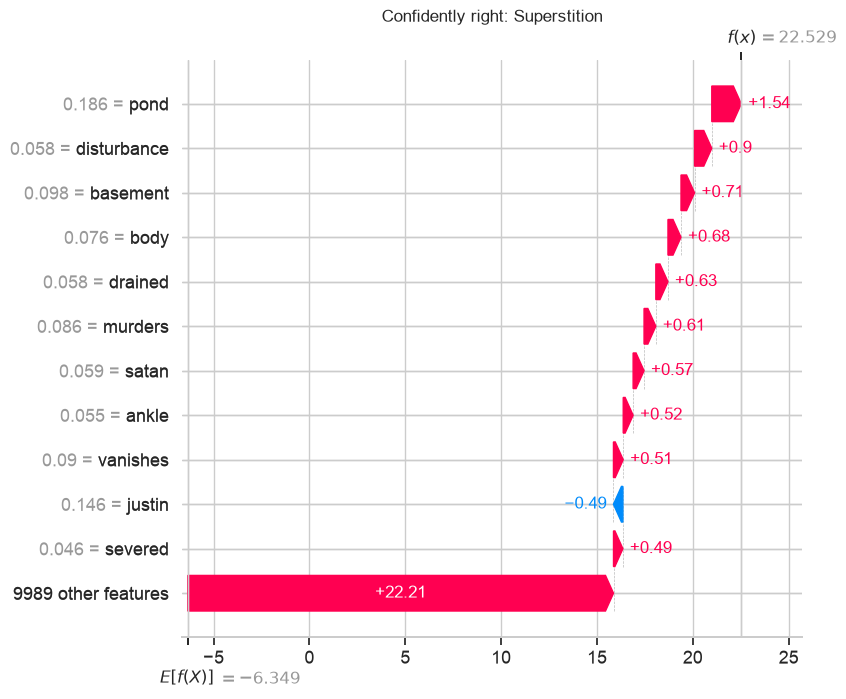

In [10]:
explain_movie(hit, "Confidently right")

**TODO (write after running):** which words drove this prediction, and do they make sense for the plot?

Badly wrong: Night of the Demons (2009)
True Horror: False   predicted P(Horror) = 1.000
Plot opening: Maddie Curtis and her friends Lilly and Suzanne are ready for a great Halloween night. Theyre going to a party thrown by their friend Angela at the notorious Broussard Mansion in New Orleans. Over eighty years ago, six people disappeared from the mansion without a trace and the owner, Evangeline Bro...


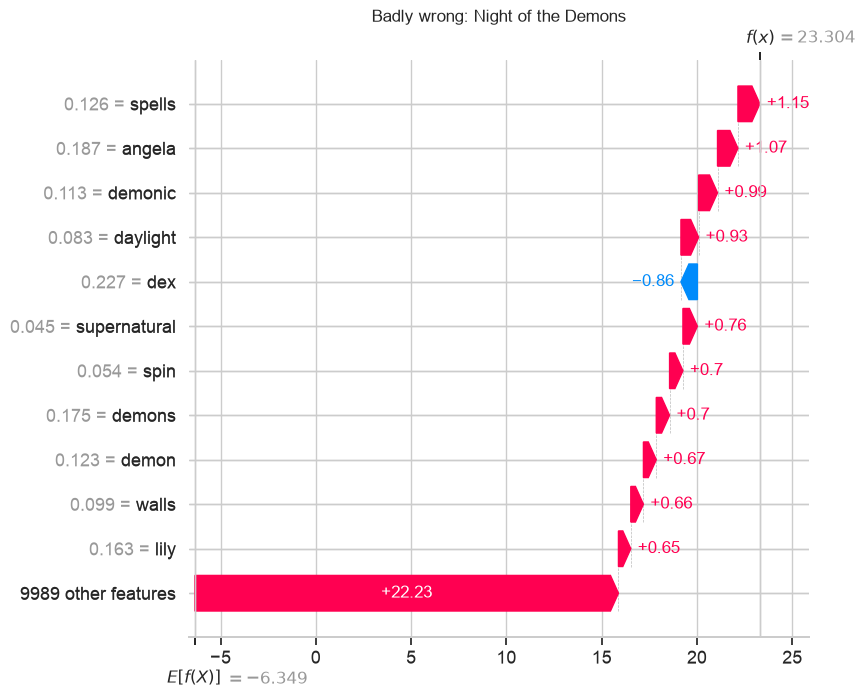

In [11]:
explain_movie(miss, "Badly wrong")

**TODO (write after running):** why did the model fail? Common causes:
- **A false positive:** a thriller or crime film full of *killed, body, blood* vocabulary that IMDB doesn't tag as Horror.
- **A false negative:** a horror film whose synopsis is mostly character drama, so the scary vocabulary is diluted.
- **Label noise:** the IMDB label itself is arguable.

Would a human reading only the synopsis make the same mistake?

## Summary
**TODO (write after running):** 3–5 bullets. What has the model actually learned (real genre semantics vs. corpus quirks such as character names)? How do coefficient importance and SHAP importance differ? What does the failure case suggest for improvement, e.g. bigrams for phrases like *haunted house*, or removing proper nouns?